# 05 - Visualizations & Simulation

Embryo development, hypergraph evolution, and learned-embedding visualizations for the trained DHGNN.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, os.path.abspath('..'))

from dhgnn_lib.cell_universe import CellUniverse
from dhgnn_lib import hyperedges, incidence, node_features, labels, training, visualization
from dhgnn_lib.dhgnn_model import DHGNNModel

RAW_DIR = '../raw_dataset'
OUTPUT_DIR = '../output_tables'
CKPT_DIR = '../checkpoints'

universe = CellUniverse.build(RAW_DIR, OUTPUT_DIR)
nfb = node_features.NodeFeatureBuilder(RAW_DIR, universe)
store = hyperedges.HyperedgeStore(RAW_DIR, OUTPUT_DIR, universe)
fate = labels.fate_labels(universe)

HIDDEN_DIM, NUM_LAYERS = 128, 3
model = DHGNNModel(num_features=nfb.num_features, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS)
model.load_state_dict(torch.load(os.path.join(CKPT_DIR, 'dhgnn_model.pt')))
model.eval()
print('loaded trained model from', os.path.join(CKPT_DIR, 'dhgnn_model.pt'))


loaded trained model from ../checkpoints\dhgnn_model.pt


## 1. Run inference across every timepoint

In [2]:
embeddings_by_t, fate_pred_by_t, present_by_t = {}, {}, {}
results = []
tps = store.timepoints
for t in tps:
    batch_t = incidence.assemble(len(universe), store.spatial(t), store.lineage(), store.functional())
    x_t = nfb.build(t)
    present = x_t[:, 5].bool()
    static_sets = {'lineage': store.lineage(), 'functional': store.functional()}
    with torch.no_grad():
        out = model(x_t, batch_t, universe=universe, present_mask=present, static_sets=static_sets, recluster=True)
    embeddings_by_t[t] = out['embeddings'].detach()
    fate_pred_by_t[t] = out['fate_logits'].argmax(-1).detach()
    present_by_t[t] = present
    m = training.compute_metrics(out, fate, present)
    m.update({'t': t, 'n_spatial_edges': store.spatial(t).num_edges})
    results.append(m)
results_df = pd.DataFrame(results).set_index('t')
results_df.head()

,fate_acc,n_eval,n_spatial_edges
t,,,
15,0.958333,24,1
30,1.000000,40,1
38,1.000000,73,1
40,1.000000,77,1
42,1.000000,80,1


## 2. Embryo development simulation

Snapshots of cell positions across development, coloured by the model's **predicted** founder-lineage fate.

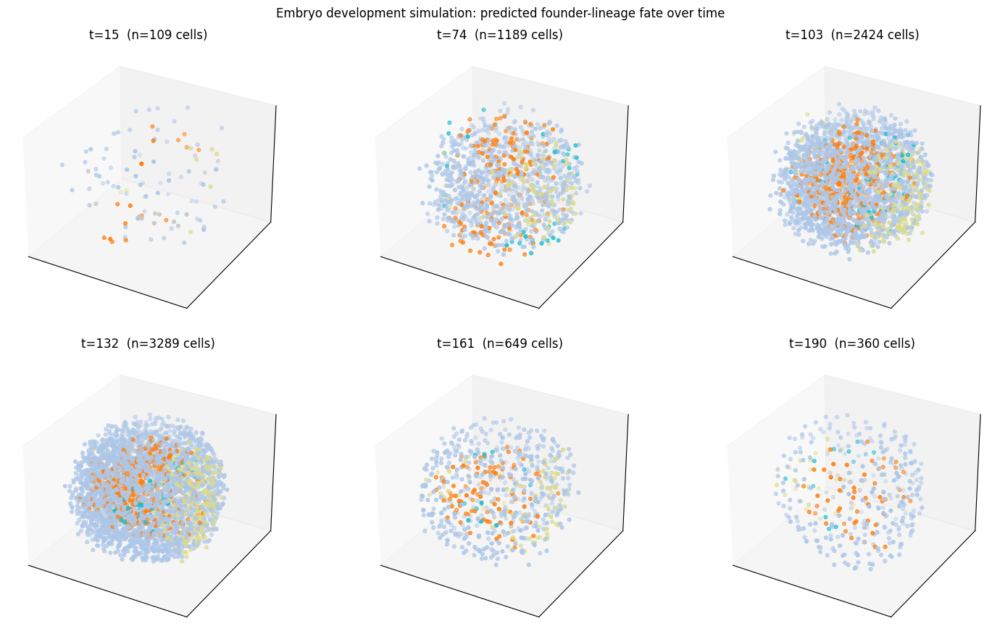

In [3]:
sample_ts = [store.timepoints[i] for i in np.linspace(0, len(store.timepoints) - 1, 6, dtype=int)]

fig = plt.figure(figsize=(15, 9))
for i, t in enumerate(sample_ts):
    ax = fig.add_subplot(2, 3, i + 1, projection='3d')
    pos = nfb.raw_positions(t)
    idxs = [universe.get(c) for c in pos['cell']]
    colors = fate_pred_by_t[t][idxs].numpy()
    ax.scatter(pos['x'], pos['y'], pos['z'], c=colors, cmap='tab20', s=12, vmin=0, vmax=len(labels.FATE_NAMES) - 1)
    ax.set_title(f't={t}  (n={len(pos)} cells)')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

fig.suptitle('Embryo development simulation: predicted founder-lineage fate over time')
fig.tight_layout()
plt.show()


### Animated 3D embryo development (interactive)

Every cell at its real (x, y, z), coloured by **founder lineage**, animated across developmental timepoints (Play button + slider). This is the canonical C. elegans developmental view and shows the pipeline's dynamic nature.

In [4]:
import plotly.io as pio
pio.renderers.default = 'notebook'
figA = visualization.embryo_development_3d(nfb, universe, fate, labels.FATE_NAMES, step=5)
figA.show()

## 3. Hypergraph evolution vs. model performance

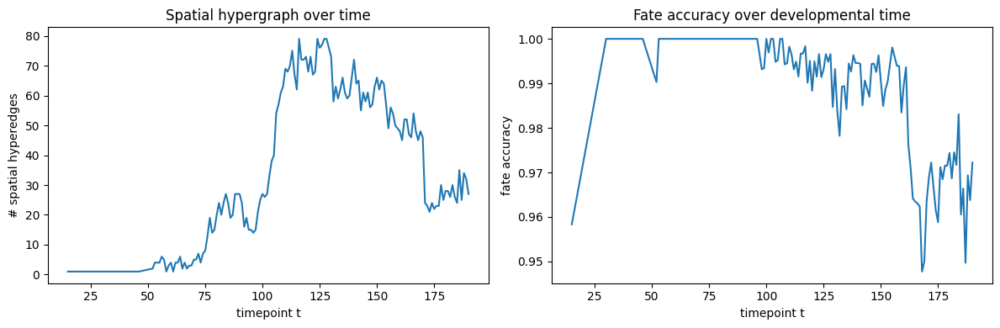

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results_df[['n_spatial_edges']].plot(ax=axes[0], legend=False)
axes[0].set_xlabel('timepoint t'); axes[0].set_ylabel('# spatial hyperedges'); axes[0].set_title('Spatial hypergraph over time')
results_df[['fate_acc']].plot(ax=axes[1], legend=False)
axes[1].set_xlabel('timepoint t'); axes[1].set_ylabel('fate accuracy'); axes[1].set_title('Fate accuracy over developmental time')
fig.tight_layout(); plt.show()

## 4. Embedding trajectories of founder-lineage cells

PCA (fit on the concatenated embeddings of these cells across all timepoints they are present) shows how each founder lineage moves through representation space during development.

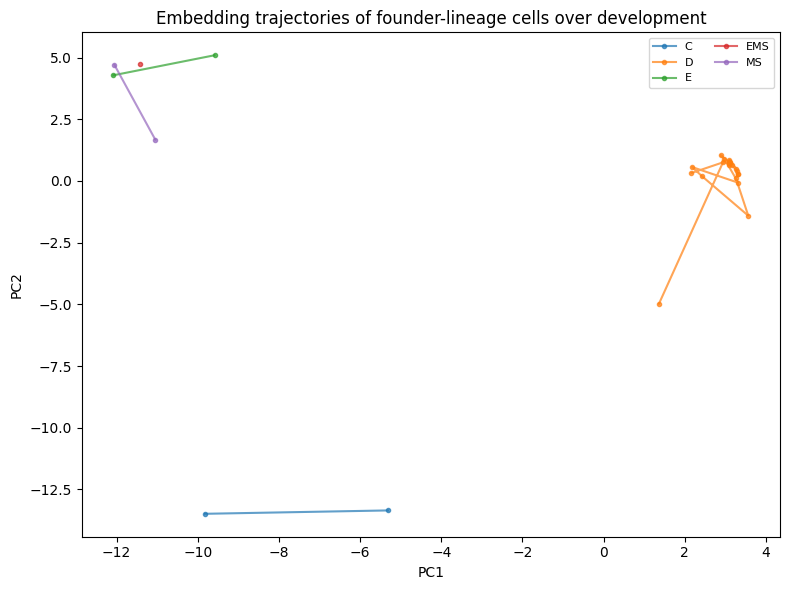

In [6]:
founder_cells = [c for c in ['AB', 'P1', 'EMS', 'MS', 'E', 'C', 'D', 'P2', 'P3', 'P4', 'Z2', 'Z3'] if c in universe]

traj_records = []
for cell in founder_cells:
    idx = universe.get(cell)
    for t in store.timepoints:
        if present_by_t[t][idx]:
            row = {'cell': cell, 't': t}
            row.update({f'd{j}': v for j, v in enumerate(embeddings_by_t[t][idx].numpy())})
            traj_records.append(row)

traj_df = pd.DataFrame(traj_records)
emb_cols = [c for c in traj_df.columns if c.startswith('d')]
coords = visualization.pca_reduce(traj_df[emb_cols].to_numpy(), 2)
traj_df['pc1'], traj_df['pc2'] = coords[:, 0], coords[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
for cell, g in traj_df.groupby('cell'):
    g = g.sort_values('t')
    ax.plot(g['pc1'], g['pc2'], marker='o', markersize=3, alpha=0.7, label=cell)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('Embedding trajectories of founder-lineage cells over development')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()


### Learned embeddings (PCA, 2D)

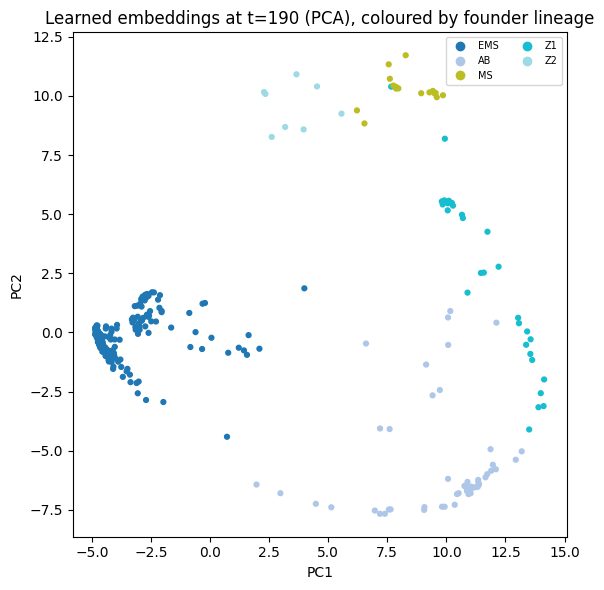

In [8]:
# Learned embeddings at the final timepoint, projected to 2D (PCA), coloured by founder lineage.
t_final = store.timepoints[-1]
present = present_by_t[t_final]
emb = embeddings_by_t[t_final][present]
fig = visualization.plot_embeddings_pca(
    emb, fate[present].numpy(), label_names=labels.FATE_NAMES,
    title=f'Learned embeddings at t={t_final} (PCA), coloured by founder lineage')
plt.show()

### Learned embeddings (PCA, 2D)

### Learned embedding space in 3D over time (animated)

The learned 128-dim embeddings reduced to 3D (PCA), each cell coloured by founder lineage, **animated across timepoints**. Visually shows the lineage clusters that the **lineage-coherence** metric scores tightening over development. Press Play or drag the slider.

In [9]:
import plotly.io as pio
pio.renderers.default = 'notebook'

# Animated across timepoints: the learned 128-d embeddings reduced to 3D (PCA
# fit once over all frames, so axes are stable). Watch founder-lineage clusters
# separate as the model refines its representation. Play button + slider.
figB = visualization.embeddings_3d_animation(
    embeddings_by_t, present_by_t, fate, labels.FATE_NAMES, step=5)
figB.show()